# Prédire l'inclusion financière en Afrique
## Partie 1 : problématique métier et analyse exploratoire des données (EDA)

**Auteur :** Médard  · **Données :** « [Financial Inclusion in Africa](https://zindi.world/competitions/financial-inclusion-in-africa/data) » (Zindi), enquêtes Finscope 2016-2018 · Kenya, Rwanda, Tanzanie, Ouganda

**Sortie de ce notebook :** Le jeu de données nettoyé `train_clean.csv`

**Avant d'exécuter :** placer `Train.csv` et `Test.csv` (téléchargés depuis Zindi) dans le même dossier que ce fichier. Ne pas publier ces fichiers ni `train_clean.csv` sur GitHub (les données restent la propriété de Zindi et de l'organisateur).

**Sommaire :** 1. Problématique métier · 2. Description du dataset · 3. Qualité des données · 4. Statistiques descriptives · 5. Visualisations · 6. Hypothèses · 7. Nettoyage et export · 8. Recommandations pour la partie 2 · 9. Limites

## 1. Problématique métier

**Contexte.** En Afrique subsaharienne, une grande partie des adultes n'a toujours pas de compte bancaire ou de mobile money. Le compte est la porte d'entrée vers l'épargne sécurisée, le paiement dématérialisé, le crédit et l'assurance, et un levier reconnu de développement économique.

**Acteurs et enjeux.**

| Acteur | Ce qu'il cherche | Enjeu |
|---|---|---|
| Banques commerciales | Identifier les segments non servis mais solvables | Élargir la clientèle, produits d'entrée de gamme |
| Microfinance et coopératives | Cibler les populations exclues, souvent rurales | Rentabilité de la proximité, risque de crédit |
| Opérateurs de mobile money | Convertir les détenteurs de téléphone en clients financiers | Croissance des usages, interopérabilité |
| Régulateurs, gouvernements | Mesurer l'exclusion et piloter les politiques d'inclusion | Suivi d'indicateurs, éducation financière |
| Personnes exclues | Accéder à des services adaptés | Sécurité de l'épargne, résilience aux chocs |

**Problème de science des données.** Classification binaire supervisée : à partir de 12 caractéristiques socio-démographiques (pays, année, milieu, téléphone, taille du ménage, âge, sexe, lien avec le chef de ménage, situation matrimoniale, éducation, emploi), prédire si la personne possède un compte bancaire (`bank_account` = 1) ou non (0). L'objectif est double : prédire une probabilité individuelle et **comprendre quels facteurs pèsent le plus**.

**Intérêt et impact.** Cibler les campagnes d'inclusion, estimer la bancarisation de zones ou profils non enquêtés, simuler l'effet d'un changement (par exemple une meilleure couverture téléphonique). Les associations observées ne prouvent pas de causalité, et le modèle décrit des profils, pas des intentions individuelles.

## 2. Description du dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
C1, C2 = '#1f4e79', '#d98a1a'

train = pd.read_csv('Train.csv')
test = pd.read_csv('Test.csv')
print('Train :', train.shape, '| Test :', test.shape, '| Total :', len(train) + len(test))
print('Colonnes présentes dans Train mais pas dans Test :', set(train.columns) - set(test.columns))
train.head()

Train : (23524, 13) | Test : (10086, 12) | Total : 33610
Colonnes présentes dans Train mais pas dans Test : {'bank_account'}


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


Le fichier **Train** contient 23 524 lignes et 13 colonnes (cible `bank_account` incluse) ; **Test** contient 10 086 lignes et 12 colonnes, **sans la cible**. L'ensemble représente 33 610 personnes, ce qui correspond aux « environ 33 600 » de la fiche de projet. Comme Test n'a pas de cible, **toutes les analyses portent sur Train** ; l'évaluation des modèles (partie 2) devra se faire sur une partie de Train mise de côté.

In [2]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   country                 23524 non-null  object
 1   year                    23524 non-null  int64 
 2   uniqueid                23524 non-null  object
 3   bank_account            23524 non-null  object
 4   location_type           23524 non-null  object
 5   cellphone_access        23524 non-null  object
 6   household_size          23524 non-null  int64 
 7   age_of_respondent       23524 non-null  int64 
 8   gender_of_respondent    23524 non-null  object
 9   relationship_with_head  23524 non-null  object
 10  marital_status          23524 non-null  object
 11  education_level         23524 non-null  object
 12  job_type                23524 non-null  object
dtypes: int64(3), object(10)
memory usage: 2.3+ MB


In [3]:
resume = (train.groupby(['country', 'year'])
          .agg(lignes_train=('uniqueid', 'size'), taux_bancarisation=('bank_account', lambda s: (s == 'Yes').mean()))
          .join(test.groupby(['country', 'year']).size().rename('lignes_test')))
resume.loc[('Total', ''), :] = [len(train), (train.bank_account == 'Yes').mean(), len(test)]
resume['taux_bancarisation'] = (resume['taux_bancarisation'] * 100).round(1).astype(str) + ' %'
resume[['lignes_train', 'lignes_test']] = resume[['lignes_train', 'lignes_test']].astype(int)
resume

,,lignes_train,taux_bancarisation,lignes_test
country,year,,,
Kenya,2018,6068,25.1 %,2601
Rwanda,2016,8735,11.5 %,3745
Tanzania,2017,6620,9.2 %,2839
Uganda,2018,2101,8.6 %,901
Total,,23524,14.1 %,10086


**Dictionnaire des variables.**

| Variable | Type | Description |
|---|---|---|
| country | catégorielle (4) | Kenya, Rwanda, Tanzanie, Ouganda |
| year | numérique discrète | 2016, 2017 ou 2018 (déterminée par le pays, sauf Kenya et Ouganda) |
| uniqueid | identifiant | Numéro du répondant, répété d'un pays à l'autre |
| bank_account | **cible** (Yes/No) | Possède un compte bancaire |
| location_type | catégorielle (2) | Rural / Urbain |
| cellphone_access | catégorielle (2) | Accès à un téléphone portable |
| household_size | numérique | Nombre de personnes du ménage |
| age_of_respondent | numérique | Âge en années |
| gender_of_respondent | catégorielle (2) | Femme / Homme |
| relationship_with_head | catégorielle (6) | Lien avec le chef de ménage |
| marital_status | catégorielle (5) | Situation matrimoniale |
| education_level | catégorielle (6) | Niveau d'éducation |
| job_type | catégorielle (10) | Type d'emploi / source de revenu |

## 3. Qualité des données

In [4]:
print('Valeurs manquantes (Train) :', train.isna().sum().sum(), '| (Test) :', test.isna().sum().sum())
print('Lignes entièrement identiques :', train.duplicated().sum())
print()
print('uniqueid distincts :', train.uniqueid.nunique(), 'pour', len(train), 'lignes')
print('(country, uniqueid) distincts :', (train.country + train.uniqueid).nunique())
print('Identifiants (pays + id) communs Train/Test :',
      len(set(train.country + train.uniqueid) & set(test.country + test.uniqueid)))
print()
feats = [c for c in train.columns if c != 'uniqueid']
print('Lignes identiques hors identifiant (variables + cible) :', train.duplicated(feats).sum(),
      f'({train.duplicated(feats).mean():.1%})')

Valeurs manquantes (Train) : 0 | (Test) : 0
Lignes entièrement identiques : 0

uniqueid distincts : 8735 pour 23524 lignes
(country, uniqueid) distincts : 23524
Identifiants (pays + id) communs Train/Test : 0

Lignes identiques hors identifiant (variables + cible) : 4429 (18.8%)


Aucune valeur manquante. L'identifiant `uniqueid` **n'est pas unique** : il se répète d'un pays à l'autre, la paire (pays, uniqueid) l'est. Nous créerons donc `id_unique`.

Les « doublons » hors identifiant sont des personnes différentes qui partagent le même profil (variables presque toutes catégorielles) : nous ne les supprimons pas. Voyons s'ils sont cohérents sur la cible.

In [5]:
cols_profil = [c for c in train.columns if c not in ('uniqueid', 'bank_account')]
g = (train.assign(y=(train.bank_account == 'Yes').astype(int))
          .groupby(cols_profil).y.agg(['size', 'mean']))
multi = g[g['size'] > 1]
conflit = multi[(multi['mean'] > 0) & (multi['mean'] < 1)]
print('Profils distincts :', len(g))
print('Profils partagés par plusieurs personnes :', len(multi), '(', int(multi['size'].sum()), 'personnes )')
print('Profils avec étiquettes contradictoires :', len(conflit), '(', int(conflit['size'].sum()), 'personnes )')

Profils distincts : 18611
Profils partagés par plusieurs personnes : 2584 ( 7497 personnes )
Profils avec étiquettes contradictoires : 484 ( 1746 personnes )


In [6]:
for c in ['country', 'location_type', 'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
          'marital_status', 'education_level', 'job_type']:
    print(train[c].value_counts().to_string(), '\n')

country
Rwanda      8735
Tanzania    6620
Kenya       6068
Uganda      2101 

location_type
Rural    14343
Urban     9181 

cellphone_access
Yes    17454
No      6070 

gender_of_respondent
Female    13877
Male       9647 

relationship_with_head
Head of Household      12831
Spouse                  6520
Child                   2229
Parent                  1086
Other relative           668
Other non-relatives      190 

marital_status
Married/Living together    10749
Single/Never Married        7983
Widowed                     2708
Divorced/Seperated          2076
Dont know                      8 

education_level
Primary education                  12791
No formal education                 4515
Secondary education                 4223
Tertiary education                  1157
Vocational/Specialised training      803
Other/Dont know/RTA                   35 

job_type
Self employed                   6437
Informally employed             5597
Farming and Fishing             5441
Remittance 

Libellés à corriger : la faute « Divorced/Seperated », et trois formulations de « ne sait pas » (`Dont know`, `Other/Dont know/RTA`, `Dont Know/Refuse to answer`) à regrouper en `Unknown`.

**Cohérence et cas atypiques.**

In [7]:
age, hh, rel = train.age_of_respondent, train.household_size, train.relationship_with_head

def tukey_haut(s):
    q1, q3 = s.quantile([.25, .75]); return q3 + 1.5 * (q3 - q1)

print('Âge : min', age.min(), '| max', age.max())
print('Moins de 18 ans :', (age < 18).sum(), f'({(age < 18).mean():.1%})')
print(f'Âge > {tukey_haut(age):.1f} (règle de Tukey) :', (age > tukey_haut(age)).sum(), '| > 90 ans :', (age > 90).sum())
print(f'Taille du ménage > {tukey_haut(hh):.1f} (Tukey) :', (hh > tukey_haut(hh)).sum(), '| max :', hh.max())
print('Mineurs chefs de ménage :', ((rel == 'Head of Household') & (age < 18)).sum(),
      '| mineurs conjoints :', ((rel == 'Spouse') & (age < 18)).sum())
print('Salariés formels sans instruction :',
      (train.job_type.str.startswith('Formally') & (train.education_level == 'No formal education')).sum())
print('« Sans revenu » bancarisés :', ((train.job_type == 'No Income') & (train.bank_account == 'Yes')).sum())
print()
print(train.groupby('relationship_with_head').age_of_respondent.describe().round(1))

Âge : min 16 | max 100
Moins de 18 ans : 939 (4.0%)
Âge > 83.5 (règle de Tukey) : 241 | > 90 ans : 57
Taille du ménage > 9.5 (Tukey) : 381 | max : 21
Mineurs chefs de ménage : 25 | mineurs conjoints : 15
Salariés formels sans instruction : 37
« Sans revenu » bancarisés : 13



                          count  mean   std   min   25%   50%   75%    max
relationship_with_head                                                    
Child                    2229.0  23.4  10.3  16.0  18.0  20.0  25.0  100.0
Head of Household       12831.0  45.1  16.4  16.0  32.0  42.0  56.0  100.0
Other non-relatives       190.0  24.4   9.7  16.0  18.0  21.0  26.0   65.0
Other relative            668.0  25.8  12.8  16.0  18.0  21.5  27.0   92.0
Parent                   1086.0  24.1  11.1  16.0  18.0  21.0  26.0  100.0
Spouse                   6520.0  35.8  12.3  16.0  27.0  33.0  42.0   95.0


Le minimum de 16 ans correspond au seuil de l'enquête. Les cas atypiques sont rares et plausibles : nous les **conservons** avec des indicateurs. La modalité **« Parent »** a un âge médian de 21 ans, proche de celui des « Child » : son libellé est ambigu, à traiter comme une simple catégorie.

**Comparaison Train / Test** (absence de décalage de distribution) :

In [8]:
ecarts = {}
for c in ['country', 'location_type', 'cellphone_access', 'gender_of_respondent', 'education_level', 'job_type']:
    e = train[c].value_counts(normalize=True).sub(test[c].value_counts(normalize=True), fill_value=0).abs().max()
    ecarts[c] = round(e * 100, 2)
print('Écart maximal de part (points de %) :', ecarts)
print('Âge moyen  Train :', round(train.age_of_respondent.mean(), 1), '| Test :', round(test.age_of_respondent.mean(), 1))
print('Modalités de Test absentes de Train :',
      {c: set(test[c]) - set(train[c]) for c in ['job_type', 'education_level', 'marital_status']})

Écart maximal de part (points de %) : {'country': np.float64(0.01), 'location_type': np.float64(0.39), 'cellphone_access': np.float64(0.75), 'gender_of_respondent': np.float64(1.02), 'education_level': np.float64(0.99), 'job_type': np.float64(0.4)}
Âge moyen  Train : 38.8 | Test : 38.3
Modalités de Test absentes de Train : {'job_type': set(), 'education_level': set(), 'marital_status': set()}


## 7 (anticipé). Nettoyage et construction du jeu de données

Le nettoyage est placé ici pour que les graphiques suivants utilisent les libellés harmonisés. Opérations : cible recodée 0/1, `id_unique` (pays + uniqueid), correction de la faute et regroupement en `Unknown`, variable `age_group`, et trois indicateurs informatifs (aucune ligne supprimée).

In [9]:
df = train.copy()
df['id_unique'] = df.country + '_' + df.uniqueid
df['bank_account'] = (df.bank_account == 'Yes').astype(int)
df['marital_status'] = df.marital_status.replace({'Divorced/Seperated': 'Divorced/Separated', 'Dont know': 'Unknown'})
df['education_level'] = df.education_level.replace({'Other/Dont know/RTA': 'Unknown'})
df['job_type'] = df.job_type.replace({'Dont Know/Refuse to answer': 'Unknown'})
df['age_group'] = pd.cut(df.age_of_respondent, [15, 24, 34, 44, 54, 64, 100],
                         labels=['16-24', '25-34', '35-44', '45-54', '55-64', '65+'])
df['flag_age_role'] = (df.relationship_with_head.isin(['Head of Household', 'Spouse']) & (df.age_of_respondent < 18)).astype(int)
df['flag_age_outlier'] = (df.age_of_respondent > 83).astype(int)
df['flag_hh_outlier'] = (df.household_size > 9).astype(int)

colonnes = ['id_unique', 'country', 'year', 'location_type', 'cellphone_access', 'household_size',
            'age_of_respondent', 'age_group', 'gender_of_respondent', 'relationship_with_head',
            'marital_status', 'education_level', 'job_type',
            'flag_age_role', 'flag_age_outlier', 'flag_hh_outlier', 'bank_account']
df = df[colonnes]
y = 'bank_account'

print(df.shape, '| valeurs manquantes :', df.isna().sum().sum(), '| id_unique unique :', df.id_unique.is_unique)
print(df[['flag_age_role', 'flag_age_outlier', 'flag_hh_outlier']].sum().to_dict())
print('Unknown -> marital :', (df.marital_status == 'Unknown').sum(), '| education :', (df.education_level == 'Unknown').sum(),
      '| job :', (df.job_type == 'Unknown').sum())

(23524, 17) | valeurs manquantes : 0 | id_unique unique : True
{'flag_age_role': 40, 'flag_age_outlier': 241, 'flag_hh_outlier': 381}
Unknown -> marital : 8 | education : 35 | job : 126


## 4. Statistiques descriptives

In [10]:
num = df[['age_of_respondent', 'household_size']]
stats = num.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['asymétrie'] = num.skew()
stats.round(2)

,mean,std,min,50%,max,asymétrie
age_of_respondent,38.81,16.52,16.0,35.0,100.0,0.84
household_size,3.80,2.23,1.0,3.0,21.0,0.99


In [11]:
print('Corrélations de Pearson :')
print(df[['age_of_respondent', 'household_size', y]].corr().round(3))
print()
for c in ['location_type', 'gender_of_respondent', 'cellphone_access']:
    print((df[c].value_counts(normalize=True) * 100).round(1).to_dict())
print('Primaire :', round((df.education_level == 'Primary education').mean() * 100, 1), '%',
      '| Supérieur :', round((df.education_level == 'Tertiary education').mean() * 100, 1), '%',
      '| Formel (privé + gouv.) :', round(df.job_type.str.startswith('Formally').mean() * 100, 1), '%')

Corrélations de Pearson :
                   age_of_respondent  household_size  bank_account
age_of_respondent              1.000          -0.130         0.019
household_size                -0.130           1.000        -0.028
bank_account                   0.019          -0.028         1.000

{'Rural': 61.0, 'Urban': 39.0}
{'Female': 59.0, 'Male': 41.0}
{'Yes': 74.2, 'No': 25.8}
Primaire : 54.4 % | Supérieur : 4.9 % | Formel (privé + gouv.) : 6.1 %


Âge et taille du ménage sont asymétriques à droite (beaucoup de jeunes adultes et de petits ménages, longue traîne). Les corrélations linéaires avec la cible sont très faibles (0,02 et -0,03), ce qui annonce des relations **non linéaires** (voir 5.3). Le répondant type est rural (61 %), une femme (59 %), avec un téléphone (74 %) et un niveau primaire (54 %).

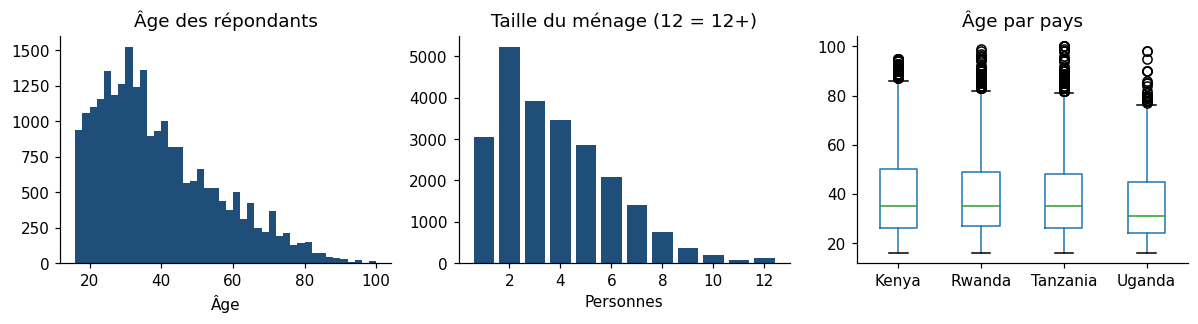

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].hist(df.age_of_respondent, bins=42, color=C1); ax[0].set_title('Âge des répondants'); ax[0].set_xlabel('Âge')
vals, cnt = np.unique(df.household_size.clip(upper=12), return_counts=True)
ax[1].bar(vals, cnt, color=C1); ax[1].set_title('Taille du ménage (12 = 12+)'); ax[1].set_xlabel('Personnes')
df.boxplot(column='age_of_respondent', by='country', ax=ax[2], grid=False); ax[2].set_title('Âge par pays'); ax[2].set_xlabel('')
plt.suptitle(''); plt.tight_layout(); plt.savefig('figures/f2_distributions.png'); plt.show()

## 5. Visualisations et premiers enseignements

### 5.1 Une cible déséquilibrée et de fortes différences entre pays

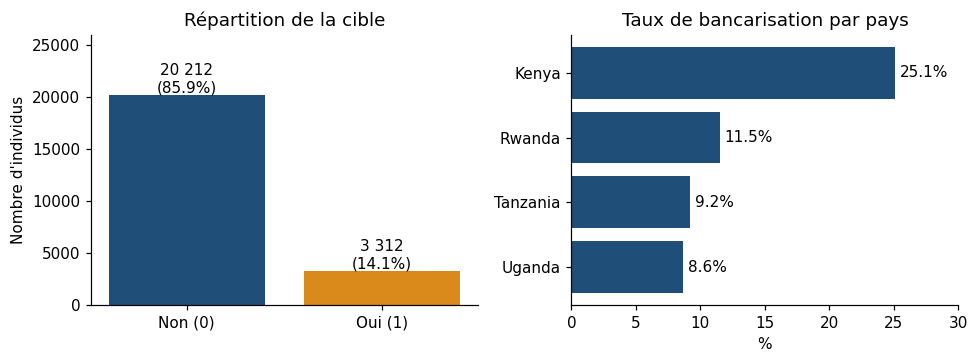

Accuracy d'un modèle qui répond toujours « non » : 0.859
location_type  Rural  Urban
country                    
Kenya           0.58   0.42
Rwanda          0.86   0.14
Tanzania        0.27   0.73
Uganda          0.72   0.28


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
vc = df[y].value_counts().sort_index()
ax[0].bar(['Non (0)', 'Oui (1)'], vc.values, color=[C1, C2])
for i, v in enumerate(vc.values):
    ax[0].text(i, v + 200, f'{v:,}\n({v / len(df):.1%})'.replace(',', ' '), ha='center')
ax[0].set_ylim(0, 26000); ax[0].set_title('Répartition de la cible'); ax[0].set_ylabel("Nombre d'individus")
g = df.groupby('country')[y].mean().sort_values()
ax[1].barh(g.index, g.values * 100, color=C1)
for i, v in enumerate(g.values):
    ax[1].text(v * 100 + .4, i, f'{v:.1%}', va='center')
ax[1].set_xlim(0, 30); ax[1].set_title('Taux de bancarisation par pays'); ax[1].set_xlabel('%')
plt.tight_layout(); plt.savefig('figures/f1_cible_pays.png'); plt.show()
print('Accuracy d\'un modèle qui répond toujours « non » :', round(1 - df[y].mean(), 3))
print(pd.crosstab(df.country, df.location_type, normalize='index').round(2))

Seuls **14,1 %** des répondants ont un compte (environ 1 sur 7). Le **Kenya** se détache (25,1 %), alors que le Rwanda (11,5 %), la Tanzanie (9,2 %) et l'Ouganda (8,6 %) sont proches. Le rôle de l'écosystème de mobile money kényan est une hypothèse plausible mais non démontrable avec ces données, et les pays diffèrent par leur composition (73 % d'urbains en Tanzanie, 14 % au Rwanda).

### 5.2 Éducation et situation professionnelle

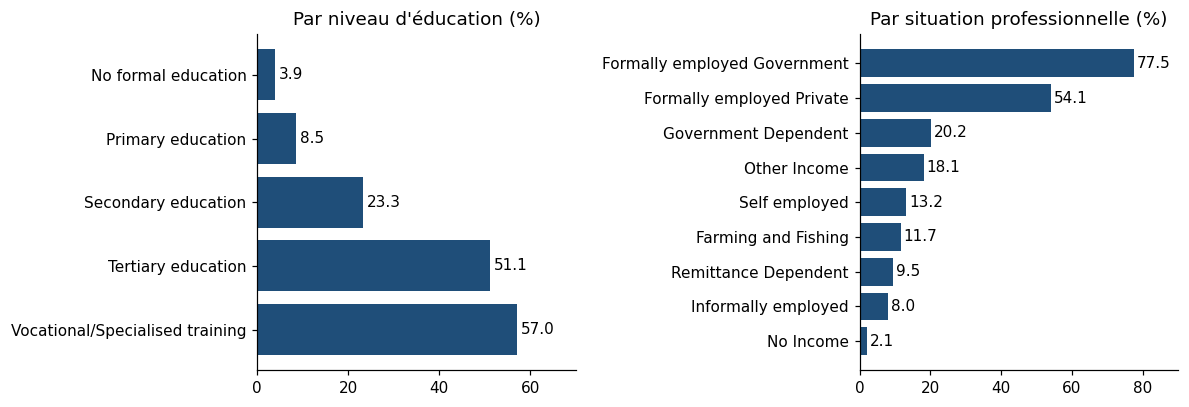

In [16]:
ordre_edu = ['No formal education', 'Primary education', 'Secondary education',
             'Tertiary education', 'Vocational/Specialised training']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
g = df[df.education_level != 'Unknown'].groupby('education_level')[y].mean().reindex(ordre_edu) * 100
ax[0].barh(g.index[::-1], g.values[::-1], color=C1); ax[0].set_title("Par niveau d'éducation (%)"); ax[0].set_xlim(0, 70)
for i, v in enumerate(g.values[::-1]): ax[0].text(v + .8, i, f'{v:.1f}', va='center')
g = df[df.job_type != 'Unknown'].groupby('job_type')[y].mean().sort_values() * 100
ax[1].barh(g.index, g.values, color=C1); ax[1].set_title('Par situation professionnelle (%)'); ax[1].set_xlim(0, 90)
for i, v in enumerate(g.values): ax[1].text(v + .8, i, f'{v:.1f}', va='center')
plt.tight_layout(); plt.savefig('figures/f4_education_job.png'); plt.show()

Le taux passe de **3,9 %** sans instruction à 8,5 % (primaire), 23,3 % (secondaire), 51,1 % (supérieur) et 57,0 % (formation professionnelle). Côté emploi, salariés du gouvernement (77,5 %) et du privé (54,1 %) sont très loin devant les indépendants (13,2 %), l'agriculture et la pêche (11,7 %), l'informel (8,0 %) et les personnes sans revenu (2,1 %). Ces deux variables sont probablement liées : un emploi formel passe souvent par un compte pour le salaire.

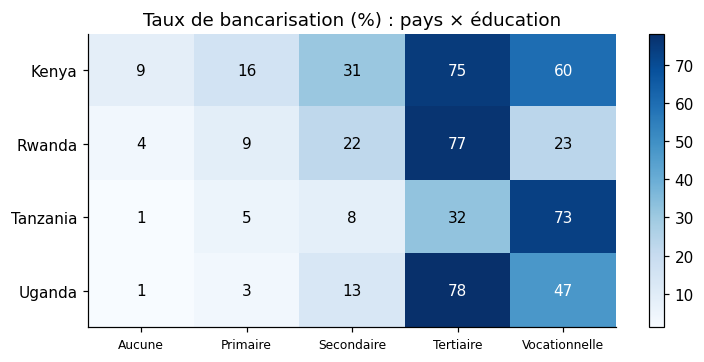

education_level  No formal education  Primary education  Secondary education  \
country                                                                        
Kenya                            941               2600                 1785   
Rwanda                          2122               4836                 1491   
Tanzania                        1133               4224                  433   
Uganda                           319               1131                  514   

education_level  Tertiary education  Vocational/Specialised training  
country                                                               
Kenya                           292                              442  
Rwanda                          177                               91  
Tanzania                        656                              171  
Uganda                           32                               99  


In [17]:
p = (df[df.education_level != 'Unknown']
     .pivot_table(index='country', columns='education_level', values=y, aggfunc='mean')[ordre_edu] * 100)
fig, ax = plt.subplots(figsize=(7, 3.4))
im = ax.imshow(p.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(5)); ax.set_xticklabels(['Aucune', 'Primaire', 'Secondaire', 'Tertiaire', 'Vocationnelle'], fontsize=8)
ax.set_yticks(range(4)); ax.set_yticklabels(p.index)
for i in range(4):
    for j in range(5):
        ax.text(j, i, f'{p.values[i, j]:.0f}', ha='center', va='center', color='white' if p.values[i, j] > 35 else 'black')
ax.set_title('Taux de bancarisation (%) : pays × éducation'); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig('figures/f7_heatmap.png'); plt.show()
print(pd.crosstab(df.country, df.education_level).loc[:, ordre_edu])

Le gradient éducatif existe dans les quatre pays mais à des niveaux très différents : au Kenya, même sans instruction formelle, 8,6 % ont un compte, contre 1,3 % en Tanzanie et en Ouganda. À éducation égale, **le pays garde un effet propre**. Attention aux petits effectifs de certaines cases (supérieur en Ouganda, par exemple).

### 5.3 L'âge : une relation en cloche

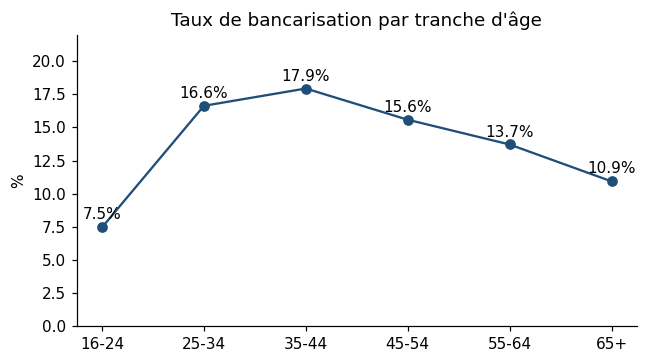

In [18]:
g = df.groupby('age_group', observed=True)[y].mean() * 100
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(g.index.astype(str), g.values, marker='o', color=C1)
for i, v in enumerate(g.values): ax.text(i, v + .6, f'{v:.1f}%', ha='center')
ax.set_ylim(0, 22); ax.set_title("Taux de bancarisation par tranche d'âge"); ax.set_ylabel('%')
plt.tight_layout(); plt.savefig('figures/f3_age.png'); plt.show()

Le taux monte de 7,5 % chez les 16-24 ans à **17,9 % entre 35 et 44 ans**, puis redescend à 10,9 % après 65 ans. Cette forme en cloche explique la faible corrélation linéaire : l'âge devra être traité de façon non linéaire (modèles à arbres, ou classes d'âge comme `age_group`).

### 5.4 Téléphone, milieu de vie et genre

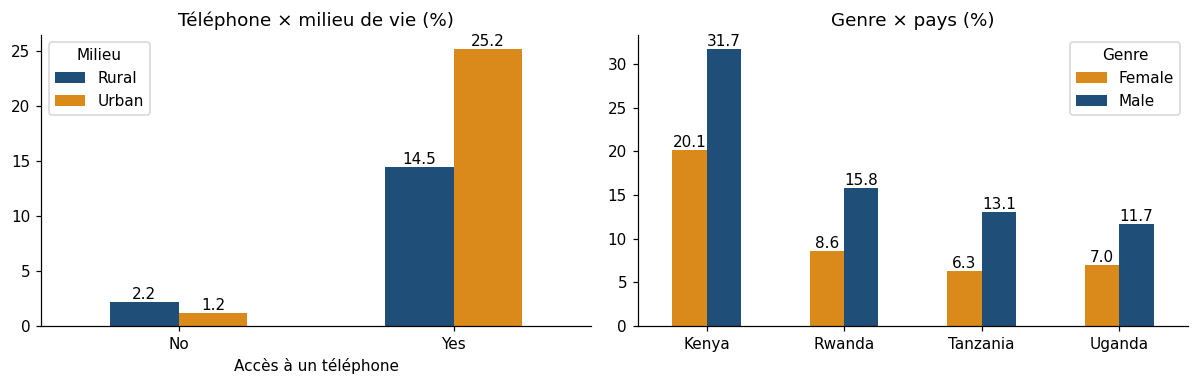

{'No': 1.7, 'Yes': 18.4}
{'Rural': 11.7, 'Urban': 17.9}
{'Female': 10.7, 'Male': 19.0}


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
g = df.groupby(['cellphone_access', 'location_type'])[y].mean().unstack() * 100
g.plot.bar(ax=ax[0], color=[C1, C2], rot=0); ax[0].set_title('Téléphone × milieu de vie (%)'); ax[0].set_xlabel('Accès à un téléphone'); ax[0].legend(title='Milieu')
for c in ax[0].containers: ax[0].bar_label(c, fmt='%.1f')
g = df.groupby(['country', 'gender_of_respondent'])[y].mean().unstack() * 100
g.plot.bar(ax=ax[1], color=[C2, C1], rot=0); ax[1].set_title('Genre × pays (%)'); ax[1].set_xlabel(''); ax[1].legend(title='Genre')
for c in ax[1].containers: ax[1].bar_label(c, fmt='%.1f')
plt.tight_layout(); plt.savefig('figures/f5_tel_genre.png'); plt.show()
print((df.groupby('cellphone_access')[y].mean() * 100).round(1).to_dict())
print((df.groupby('location_type')[y].mean() * 100).round(1).to_dict())
print((df.groupby('gender_of_respondent')[y].mean() * 100).round(1).to_dict())

**Téléphone** : 18,4 % des personnes avec téléphone sont bancarisées, contre 1,7 % de celles sans. C'est l'écart le plus net pour une variable binaire : le téléphone est probablement un intermédiaire d'accès (mobile money) et un marqueur de niveau de vie.

**Milieu** : les urbains sont plus bancarisés (17,9 % contre 11,7 %), mais chez les personnes sans téléphone ils ne sont pas mieux lotis que les ruraux (1,2 % contre 2,2 %). L'avantage urbain se concentre chez ceux qui ont un téléphone (25,2 % contre 14,5 %).

**Genre** : hommes 19,0 % contre femmes 10,7 %, et l'écart se retrouve dans chaque pays. Une partie vient peut-être des différences d'éducation et d'emploi, à tester en partie 2.

### 5.5 Force d'association avec la cible (V de Cramér)

p-valeur maximale des tests du khi-deux : 1.0e-40


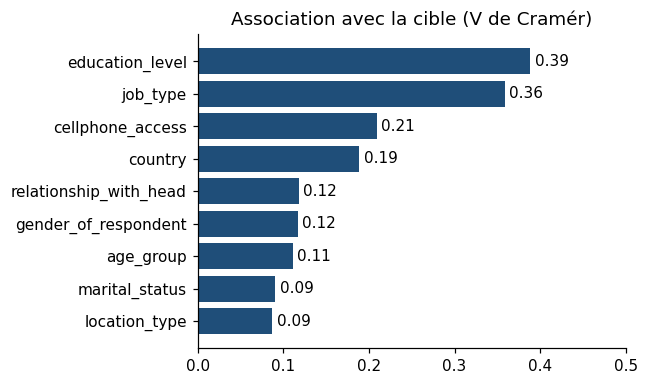

In [20]:
def cramer_v(a, b):
    t = pd.crosstab(a, b); chi2 = chi2_contingency(t)[0]; n = t.values.sum()
    return np.sqrt(chi2 / n / (min(t.shape) - 1))

cat = ['country', 'location_type', 'cellphone_access', 'gender_of_respondent', 'relationship_with_head',
       'marital_status', 'education_level', 'job_type', 'age_group']
v = pd.Series({c: cramer_v(df[c], df[y]) for c in cat}).sort_values()
pvals = {c: chi2_contingency(pd.crosstab(df[c], df[y]))[1] for c in cat}
print('p-valeur maximale des tests du khi-deux :', f'{max(pvals.values()):.1e}')

fig, ax = plt.subplots(figsize=(6, 3.6)); ax.barh(v.index, v.values, color=C1)
for i, x in enumerate(v.values): ax.text(x + .005, i, f'{x:.2f}', va='center')
ax.set_title('Association avec la cible (V de Cramér)'); ax.set_xlim(0, .5)
plt.tight_layout(); plt.savefig('figures/f6_cramer.png'); plt.show()

Éducation (0,39) et emploi (0,36) dominent, suivis du téléphone (0,21) et du pays (0,19). Le V de Cramér mesure une **association**, pas un effet causal ni une importance de variable dans un modèle.

Autres variables : chefs de ménage 17,7 % contre conjoints 10,7 %, enfants 8,7 % et « Parent » 6,0 % ; mariés 17,4 % contre veufs 9,0 % ; taille du ménage à effet faible (personnes seules 19,1 %, puis 12 à 15 % pour 2 à 7 personnes).

In [21]:
print((df.groupby('relationship_with_head')[y].mean() * 100).round(1).sort_values().to_dict())
print((df.groupby('marital_status')[y].mean() * 100).round(1).sort_values().to_dict())
(df.groupby('household_size')[y].agg(['mean', 'size']).head(12).round(3))

{'Parent': 6.0, 'Child': 8.7, 'Other relative': 9.9, 'Other non-relatives': 10.5, 'Spouse': 10.7, 'Head of Household': 17.7}
{'Widowed': 9.0, 'Divorced/Separated': 11.3, 'Single/Never Married': 12.1, 'Married/Living together': 17.4, 'Unknown': 25.0}


,mean,size
household_size,,
1,0.191,3057
2,0.118,5229
3,0.143,3920
4,0.144,3474
5,0.150,2853
6,0.132,2096
7,0.126,1400
8,0.115,751
9,0.102,363


## 6. Hypothèses

| N° | Hypothèse | Appui dans les données | À vérifier en partie 2 |
|---|---|---|---|
| H1 | L'éducation et l'emploi formel sont les meilleurs prédicteurs | V = 0,39 et 0,36 | Importance des variables, effet à pays et téléphone égaux |
| H2 | Le téléphone est la porte d'entrée vers le compte | 1,7 % contre 18,4 % | Interactions téléphone × milieu et téléphone × pays |
| H3 | Le pays a un effet propre, surtout le Kenya | 25,1 % contre 8,6-11,5 % | Performance du modèle sans la variable pays |
| H4 | Un écart de genre subsiste à profil équivalent | 19,0 % contre 10,7 %, dans les 4 pays | Importance du genre une fois éducation et emploi inclus |
| H5 | L'âge agit de façon non linéaire (max 35-44 ans) | 7,5 % / 17,9 % / 10,9 % | Régression logistique contre modèles à arbres |
| H6 | L'effet urbain passe surtout par le téléphone et le niveau de vie | Pas d'avantage urbain sans téléphone | Coefficients avec et sans téléphone |

## 7. Export du jeu de données nettoyé

In [23]:
df.to_csv('train_clean.csv', index=False)
pd.read_csv('train_clean.csv').head()

,id_unique,country,year,location_type,cellphone_access,household_size,age_of_respondent,age_group,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type,flag_age_role,flag_age_outlier,flag_hh_outlier,bank_account
0,Kenya_uniqueid_1,Kenya,2018,Rural,Yes,3,24,16-24,Female,Spouse,Married/Living together,Secondary education,Self employed,0,0,0,1
1,Kenya_uniqueid_2,Kenya,2018,Rural,No,5,70,65+,Female,Head of Household,Widowed,No formal education,Government Dependent,0,0,0,0
2,Kenya_uniqueid_3,Kenya,2018,Urban,Yes,5,26,25-34,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed,0,0,0,1
3,Kenya_uniqueid_4,Kenya,2018,Rural,Yes,5,34,25-34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private,0,0,0,0
4,Kenya_uniqueid_5,Kenya,2018,Urban,No,8,26,25-34,Male,Child,Single/Never Married,Primary education,Informally employed,0,0,0,0


Le fichier `train_clean.csv` contient **23 524 lignes et 17 colonnes**, sans valeur manquante, cible `bank_account` en dernière colonne.

## 8. Recommandations pour la partie 2 (modélisation)

- **Ne pas utiliser `id_unique` comme variable explicative** (identifiant seulement).
- **Garder `country` et ignorer `year`** : l'année est déterminée par le pays (sauf Kenya/Ouganda, tous deux en 2018).
- **Découpage stratifié sur la cible** (et idéalement le pays) : la classe positive ne pèse que 14,1 %.
- **Métriques** : rappel, F1, AUC-ROC et AUC-PR en plus de l'accuracy (la ligne de base « toujours non » donne 85,9 %).
- **Déséquilibre** : comparer pondération des classes, sur-échantillonnage (SMOTE) et sous-échantillonnage, uniquement sur le jeu d'entraînement.
- **Encodage** : one-hot pour les variables nominales ; éducation éventuellement ordinale. Les modalités `Unknown` sont très rares.
- **Indicateurs `flag_*`** : informatifs, ne pas supprimer ces lignes sans test de sensibilité.

## 9. Limites et précautions

- **Pays et année confondus** : impossible de séparer l'effet du pays de celui de l'année d'enquête.
- **Couverture** : Afrique de l'Est uniquement (pas le Bénin), données de 2016 à 2018, avant l'essor récent du mobile money.
- **Associations, pas causalité** : éducation, emploi et téléphone sont corrélés entre eux, les taux bruts mélangent plusieurs effets.
- **Informations limitées** : pas de revenu, de distance à une agence ni d'usage du mobile money ; 484 profils contradictoires plafonnent la performance.
- **Variable « Parent »** : libellé ambigu.
- **Conditions d'utilisation** : les données restent la propriété de Zindi et de l'organisateur ; à vérifier avant toute publication. Ne pas déposer `Train.csv`, `Test.csv` ni `train_clean.csv` sur le dépôt GitHub public.